# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

The data that we are working with in this assignment is sounds, specifically sounds coming from hand claps, key chains and keyboard typing. The goal is to train a model that, taking sound from a microphone, can distinguish between these sounds by looking at their mel spectrogram.

The dataset was generated by us applying the following method:
* Finding 5 different keyboards, 5 different keychains and 5 different ways to clap hands (rythm, distance from mic)
* Recording a 90s recording of each one of the items. 450s of data per class.
* Split into snippet of 3s. 150 samples per class
* One out of the five recordings per class is selected for testing. The data is then split in training (80%) and testing (20%).

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa
import math

DATADIR = "sound_database"
DATASET_PATH = "dataset"
CATEGORIES = ['Claps', 'Keyboard', 'Keys']
snippet_length = 3 #seconds     # X resolution of the spectrograms (basically image width) depends on sampling rate
N_MELS = 128                    # Y resolution of the spectrograms (basically image height)

The following function takes .wav audio samples and creates a mel spectrogram out of them. This will be the data from which out CNN will be trained on.

In [10]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    mel_spec = mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    return mel_spec[np.newaxis, ...]

The following function splits the recordings and saves a spectrogram for each snippet in the "dataset" folder.

In [11]:
def split_rec_and_create_dataset():
    # 1. Create the main folder if it doesn't exist
    if not os.path.exists(DATASET_PATH):
        os.makedirs(DATASET_PATH)
        print(f"Created folder: {DATASET_PATH}")
    
    count = 0
    
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        
        if not os.path.exists(path):
            print(f"Skipping {category}: Folder not found at {path}")
            continue

        print(f"Processing category: {category}")

        for fname in os.listdir(path):
            if not fname.lower().endswith('.wav'):
                continue
                
            file_path = os.path.join(path, fname)
            
            # Get the clean filename without extension (e.g. "Keys3")
            base_name = os.path.splitext(fname)[0]
            
            try:
                audio, sr = librosa.load(file_path, sr=None)
                
                total_samples = len(audio)
                samples_per_chunk = int(snippet_length * sr)
                parts = math.ceil(total_samples / samples_per_chunk)
                
                for i in range(parts):
                    start = i * samples_per_chunk
                    end = start + samples_per_chunk
                    
                    chunk_audio = audio[start:end]
                    
                    #Zero Padding
                    if len(chunk_audio) < samples_per_chunk:
                        # Calculate how many zeros we need
                        padding_needed = samples_per_chunk - len(chunk_audio)
                        
                        # Pad the array with zeros (silence) at the end
                        # mode='constant' fills with the constant value (default 0)
                        chunk_audio = np.pad(chunk_audio, (0, padding_needed), mode='constant')
                    
                    # Convert to spectrogram (returns 4D tensor)
                    spectro = convert_to_spectrogram(chunk_audio, sr, N_MELS, fmax=8000)
                    
                    # --- SAVING LOGIC ---
                    
                    # 1. Squeeze the dimensions
                    # Your function returns (1, 128, time, 1), but to save as an image
                    # we need a 2D array: (128, time)
                    image_data = spectro.squeeze()
                    
                    # 2. Construct the filename: "Keys3_8.png"
                    # We use i+1 so the first part is "Keys3_1" instead of "Keys3_0"
                    out_name = f"{base_name}_{i+1}.png"
                    out_path = os.path.join(DATASET_PATH, out_name)
                    
                    # 3. Save as image
                    # origin='lower' puts low frequencies at the bottom (standard for audio)
                    # cmap='viridis' or 'magma' gives it the color. Use 'gray' for black/white.
                    plt.imsave(out_path, image_data, origin='lower', cmap='magma')
                    
                    count += 1
                
            except Exception as e:
                print(f"Error processing {fname}: {e}")
                
    print(f"Done! Saved {count} spectrogram images to '{DATASET_PATH}'")

split_rec_and_create_dataset()

Processing category: Claps
Processing category: Keyboard
Processing category: Keys
Done! Saved 450 spectrogram images to 'dataset'


The following function loads all the saved spectrograms and creates a testset and a trainset.

In [ ]:
import os
import cv2
import numpy as np
from tensorflow.keras.utils import to_categorical

IMG_HEIGHT = N_MELS  # Must match your saved images
IMG_WIDTH = 259   # Must match your saved images

def load_and_split_dataset():
    # Initialize empty lists
    x_train, y_train = [], []
    x_test, y_test = [], []

    print("Loading images...")

    for img_name in os.listdir(DATASET_PATH):
        # Skip non-image files
        if not img_name.endswith(".png"):
            continue

        # --- PARSING THE FILENAME ---
        # Example filename: "Keys5_19.png"
        
        # 1. Split "Keys5" from "19.png"
        parts = img_name.split('_') 
        prefix = parts[0] # "Keys5"
        
        # 2. Identify the Category and Recording ID
        category = None
        for cat in CATEGORIES:
            if prefix.startswith(cat):
                category = cat
                break
        
        if category is None:
            print(f"Skipping {img_name}: Could not match category")
            continue
            
        # 3. Extract the recording number (Remove "Keys" from "Keys5" -> "5")
        recording_id = prefix.replace(category, "")
        
        # 4. Get the numerical label (0, 1, or 2)
        label = CATEGORIES.index(category)

        # --- LOAD IMAGE ---
        img_path = os.path.join(DATASET_PATH, img_name)
        
        # Read as GRAYSCALE
        # This ignores the Magma colors and loads strictly based on brightness
        img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        # Safety resize (ensures stacking doesn't crash if one image is off by 1 pixel)
        img_array = cv2.resize(img_array, (IMG_WIDTH, IMG_HEIGHT))
        
        # Normalize pixel values to be between 0 and 1 (Best practice for ML)
        img_array = img_array / 255.0

        # --- SPLIT INTO TRAIN VS TEST ---
        # If the recording ID is '5', it goes to TEST. Everything else goes to TRAIN.
        if recording_id == '5':
            x_test.append(img_array)
            y_test.append(label)
        else:
            x_train.append(img_array)
            y_train.append(label)

    # --- CREATE THE "STACKS" (Convert lists to Numpy Arrays) ---
    x_train = np.array(x_train)
    y_train = np.array(y_train)
    x_test = np.array(x_test)
    y_test = np.array(y_test)
    
    # We need to add a dimension to specify the number of channels (1)
    x_train = x_train[..., np.newaxis]
    x_test = x_test[..., np.newaxis]

    # --- ONE-HOT ENCODING ---
    # Converts label "0" to "[1, 0, 0]"
    y_train = to_categorical(y_train, num_classes=len(CATEGORIES))
    y_test = to_categorical(y_test, num_classes=len(CATEGORIES))

    return x_train, y_train, x_test, y_test

# Run the function
x_train, y_train, x_test, y_test = load_and_split_dataset()

# --- VERIFY THE RESULTS ---
print(f"\n--- Data Loaded ---")
print(f"Training Data Shape (x_train): {x_train.shape}") # Should look like (Num_Samples, Num_Mels, Num_SoundSamples)   (360, 128, 259)
print(f"Training Labels Shape (y_train): {y_train.shape}") #Should look like (Num_Samples, Num_Categories)              (360, 3)
print(f"Test Data Shape (x_test):      {x_test.shape}")
print(f"Test Labels Shape (y_test):      {y_test.shape}")

Loading images...
[1. 0. 0.]

--- Data Loaded ---
Training Data Shape (x_train): (360, 128, 259, 1)
Training Labels Shape (y_train): (360, 3)
Test Data Shape (x_test):      (90, 128, 259, 1)
Test Labels Shape (y_test):      (90, 3)


## Network architecture

In [35]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(N_MELS, IMG_WIDTH, 1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
 
    Flatten(),
    Dense(64, activation='relu'),
    #Dropout(0.5),
    
    Dense(len(CATEGORIES), activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Pedro\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)              │ (None, 126, 257, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 126, 257, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 63, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 61, 126, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 61, 126, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 30, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 28, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 28, 61, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 14, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 53760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │     3,440,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,534,467 (13.48 MB)

 Trainable params: 3,534,019 (13.48 MB)

 Non-trainable params: 448 (1.75 KB)

## Model training

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6435 - loss: 7.7403
Epoch 1: val_loss improved from None to 2.45014, saving model to best_audio_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8194 - loss: 4.0713 - val_accuracy: 0.6667 - val_loss: 2.4501
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9885 - loss: 0.1609
Epoch 2: val_loss did not improve from 2.45014
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9917 - loss: 0.1558 - val_accuracy: 0.3333 - val_loss: 19.2537
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9998 - loss: 0.0027    
Epoch 3: val_loss did not improve from 2.45014
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9972 - loss: 0.0318 - val_accuracy: 0.3333 - val_loss: 35.7615
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9965 - loss: 0.0098
Epoch 4: val_loss did not improve from 2.45014
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9944 - loss: 0.0147 - val_accur

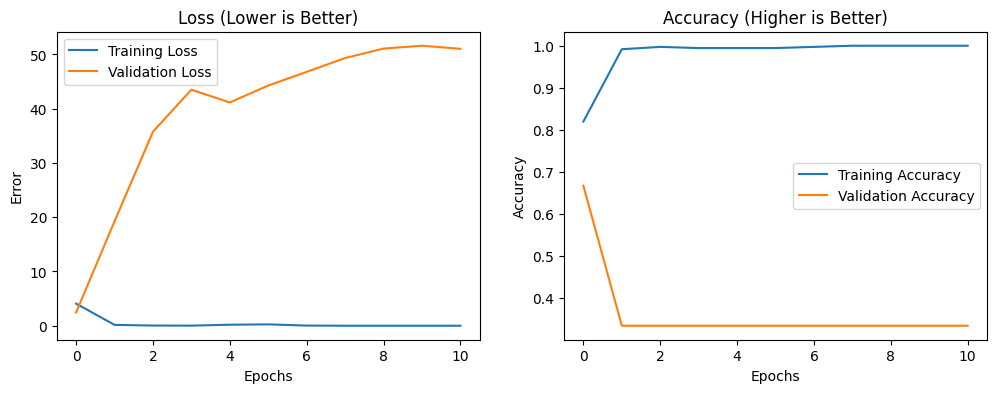

In [36]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. STOPPING: Stop if validation loss doesn't improve for 10 epochs (patience)
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True, # reverts to the best epoch automatically
    verbose=1
)

# 2. SAVING: Save the best model to a file
checkpoint = ModelCheckpoint(
    'best_audio_model.keras', 
    monitor='val_loss', 
    save_best_only=True, 
    verbose=1
)

# 3. FITTING
history = model.fit(
    x_train, y_train,
    epochs=100,            # Set high, let EarlyStopping decide when to end
    batch_size=32,         # 32 is standard. For small data, 16 is also okay.
    validation_data=(x_test, y_test),
    callbacks=[checkpoint, early_stop]
)

import matplotlib.pyplot as plt

# 1. Plot the "Loss"
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1) # Left graph
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss (Lower is Better)')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.legend()

# 2. Plot the "Accuracy"
plt.subplot(1, 2, 2) # Right graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy (Higher is Better)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 311ms/step

Confusion Matrix:
[[ 0 30  0]
 [ 0 30  0]
 [ 0  0 30]]

Classification Report:
              precision    recall  f1-score   support

       Claps       0.00      0.00      0.00        30
    Keyboard       0.50      1.00      0.67        30
        Keys       1.00      1.00      1.00        30

    accuracy                           0.67        90
   macro avg       0.50      0.67      0.56        90
weighted avg       0.50      0.67      0.56        90



c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


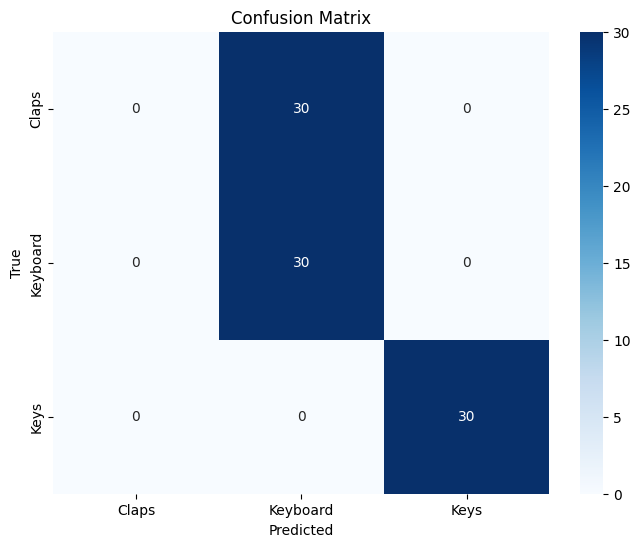

In [37]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the model's predictions (these will be probabilities)
predictions = model.predict(x_test)

# 2. Convert One-Hot Encoded labels back to Single Integers
# Example: [0, 1, 0] -> 1 (Keyboard)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 3. Print the text evaluation
print("\nConfusion Matrix:")
print(confusion_matrix(y_true_classes, y_pred_classes))

print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=CATEGORIES))

# 4. (Optional) Plot a nice heatmap for the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Live data Collection & Actuators 



In [ ]:
import os
import time
import numpy as np
import librosa
import sounddevice as sd
from scipy.io.wavfile import write
import tensorflow as tf
import Jetson.GPIO as GPIO

# --- CONFIGURATION ---
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, "best_audio_model.h5")
OUTPUT_FILENAME = os.path.join(BASE_DIR, "live_recording.wav")

# STRICT TIMING SETTINGS
RECORD_SECONDS = 3       # Exactly 3 seconds
SAMPLE_RATE = 44100      # Must match training data
CATEGORIES = ['Claps', 'Keyboard', 'Keys']
N_MELS = 128

# --- GPIO SETUP ---
LED_CLAPS = 11      # Board Pin 11
LED_KEYBOARD = 13   # Board Pin 13
LED_KEYS = 15       # Board Pin 15

def setup_gpio():
    GPIO.setmode(GPIO.BOARD)
    GPIO.setup(LED_CLAPS, GPIO.OUT, initial=GPIO.LOW)
    GPIO.setup(LED_KEYBOARD, GPIO.OUT, initial=GPIO.LOW)
    GPIO.setup(LED_KEYS, GPIO.OUT, initial=GPIO.LOW)

def trigger_led(category):
    mapping = {'Claps': LED_CLAPS, 'Keyboard': LED_KEYBOARD, 'Keys': LED_KEYS}
    pin = mapping.get(category)
    
    if pin:
        print(f"--> Lighting LED for {category} (Pin {pin})")
        GPIO.output(pin, GPIO.HIGH)
        time.sleep(4) 
        GPIO.output(pin, GPIO.LOW)
    else:
        print(f"No LED configured for: {category}")

# --- STRICT 3S RECORDING ---
def record_audio_fixed_duration():
    print(f"\n[INFO] Get ready...")
    time.sleep(1) # Give user a split second to prepare
    
    print(f"[REC]  Recording for {RECORD_SECONDS}s NOW!")
    
    # Calculate exact number of frames for 3 seconds
    frames = int(RECORD_SECONDS * SAMPLE_RATE)
    
    # Non-blocking recording start
    recording = sd.rec(frames, samplerate=SAMPLE_RATE, channels=1)
    
    # Wait exactly for the duration
    sd.wait() 
    
    print("[STOP] Recording complete.")
    
    # Save (Overwrite)
    write(OUTPUT_FILENAME, SAMPLE_RATE, recording)

def preprocess_audio(file_path):
    # Load with strict duration enforcement
    audio, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=RECORD_SECONDS)
    
    # Pad if shorter than 3s (rare, but good for safety)
    target_length = int(RECORD_SECONDS * SAMPLE_RATE)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)))
    else:
        audio = audio[:target_length]
        
    mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=N_MELS, fmax=8000)
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())
    mel_spec = mel_spec[..., np.newaxis]
    return mel_spec[np.newaxis, ...]

# --- MAIN ---
def main():
    setup_gpio()

    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError("Model file missing.")

    print("[INFO] Loading Model...")
    model = tf.keras.models.load_model(MODEL_PATH)
    print ("[INFO] Model loaded successfully.")

    try:
        # 1. Capture 3s
        record_audio_fixed_duration()
        
        # 2. Process
        spectrogram = preprocess_audio(OUTPUT_FILENAME)
        
        # 3. Predict
        prediction = model.predict(spectrogram)
        class_index = np.argmax(prediction)
        result_label = CATEGORIES[class_index]
        
        print(f"\n>>> RESULT: {result_label} <<<\n")
        
        # 4. LED
        trigger_led(result_label)
        
    except Exception as e:
        print(f"[ERROR] {e}")
    finally:
        GPIO.cleanup()

if __name__ == "__main__":
    main()

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [16]:
# import pyaudio
# import wave

# # Configuration parameters
# FORMAT = pyaudio.paInt16  # 16-bit resolution
# CHANNELS = 1              # Mono recording
# RATE = 44100              # Sample rate (44.1kHz is standard)
# CHUNK = 1024              # Buffer size
# RECORD_SECONDS = 5        # Duration of recording
# OUTPUT_FILENAME = "test_recording.wav"

# audio = pyaudio.PyAudio()

# # Start Recording
# stream = audio.open(format=FORMAT, channels=CHANNELS,
#                     rate=RATE, input=True,
#                     frames_per_buffer=CHUNK)

# print("Recording...")

# frames = []

# for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
#     data = stream.read(CHUNK)
#     frames.append(data)

# print("Finished recording.")

# # Stop and close the stream
# stream.stop_stream()
# stream.close()
# audio.terminate()

# # Save the recorded data as a WAV file 
# # (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
# with wave.open(OUTPUT_FILENAME, 'wb') as wf:
#     wf.setnchannels(CHANNELS)
#     wf.setsampwidth(audio.get_sample_size(FORMAT))
#     wf.setframerate(RATE)
#     wf.writeframes(b''.join(frames))

# print(f"File saved as {OUTPUT_FILENAME}")